In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pandas import read_csv
import math
from keras.models import Sequential
from keras.layers import Dense
from keras.layers import LSTM
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
from keras.layers import Dense, Activation, Dropout, Reshape, Permute
import time #helper libraries
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pandas import read_csv
import math
import keras
from keras.models import Sequential
from keras.layers import Dense
from keras.layers import LSTM
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
from keras.layers import Dense, Activation, Dropout
import time #helper libraries
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pandas import read_csv
import math
import keras
from keras.models import Sequential
from keras.layers import Dense
from keras.layers import LSTM
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
from keras.layers import Dense, Activation, Dropout
import time #helper libraries
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import itertools

import os

2026-02-08 20:19:15.240032: I tensorflow/core/util/port.cc:111] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-02-08 20:19:15.251974: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2026-02-08 20:19:15.291555: E tensorflow/compiler/xla/stream_executor/cuda/cuda_dnn.cc:9342] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-02-08 20:19:15.291583: E tensorflow/compiler/xla/stream_executor/cuda/cuda_fft.cc:609] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-02-08 20:19:15.291614: E tensorflow/compiler/xla/stream_executor/cuda/cuda_blas.cc:1518] Unable to register cuBLAS factory: Attempting to regi

In [4]:
df1_class = pd.read_csv("LSTM_Model1_Classification__simulation.csv")
df2_class = pd.read_csv("LSTM_Model2_Classification__simulation.csv")
df1_reg = pd.read_csv("LSTM_Model1_Regression__simulation.csv")
df2_reg = pd.read_csv("LSTM_Model2_Regression__simulation.csv")

In [6]:
df2_class

,n_repeat,lookback,test_size,test_acc
0,0,15,0.5,0.659701
1,1,15,0.5,0.646766
2,2,15,0.5,0.674627
3,3,15,0.5,0.624876
4,4,15,0.5,0.647761
...,...,...,...,...
175,5,135,0.3,0.687582
176,6,135,0.3,0.763399
177,7,135,0.3,0.718954
178,8,135,0.3,0.724183


In [10]:
df2_class["test_acc"].max()

0.8235897435897436

In [7]:
import pandas as pd

# Drop rows with missing values
df2_class = df2_class.dropna()

# Ensure correct types
df2_class['n_repeat'] = df2_class['n_repeat'].astype(int)
df2_class['lookback'] = df2_class['lookback'].astype(int)
df2_class['test_size'] = df2_class['test_size'].astype(float)
df2_class['test_acc'] = df2_class['test_acc'].astype(float)

# Optional: remove duplicates
df2_class = df2_class.drop_duplicates()

# Reset index
df2_class = df2_class.reset_index(drop=True)

print(df2_class.head())


   n_repeat  lookback  test_size  test_acc
0         0        15        0.5  0.659701
1         1        15        0.5  0.646766
2         2        15        0.5  0.674627
3         3        15        0.5  0.624876
4         4        15        0.5  0.647761


In [12]:
# Group by lookback and test_size, then compute mean and std of test_acc
stats = df2_class.groupby(['lookback', 'test_size'])['test_acc'].agg(['max','mean', 'std']).reset_index()

# Find the best combination (highest mean accuracy)
best = stats.loc[stats['max'].idxmax()]

print("Best configuration:")
print(best)


Best configuration:
lookback     30.000000
test_size     0.300000
max           0.823590
mean          0.787897
std           0.030147
Name: 2, dtype: float64


In [13]:
import pandas as pd

# Drop rows with missing values
df1_class = df1_class.dropna()

# Ensure correct types
df1_class['n_repeat'] = df1_class['n_repeat'].astype(int)
df1_class['lookback'] = df1_class['lookback'].astype(int)
df1_class['test_size'] = df1_class['test_size'].astype(float)
df1_class['test_acc'] = df1_class['test_acc'].astype(float)

# Optional: remove duplicates
df1_class = df1_class.drop_duplicates()

# Reset index
df1_class = df1_class.reset_index(drop=True)

# Group by lookback and test_size, then compute mean and std of test_acc
stats = df1_class.groupby(['lookback', 'test_size'])['test_acc'].agg(['max','mean', 'std']).reset_index()

# Find the best combination (highest mean accuracy)
best = stats.loc[stats['max'].idxmax()]

print("Best configuration:")
print(best)


Best configuration:
lookback     30.000000
test_size     0.300000
max           0.779487
mean          0.738051
std           0.036507
Name: 2, dtype: float64


In [5]:
#df1_class = df1_class.apply(pd.to_numeric, errors="coerce")

#df1_class_avg = df1_class.drop(["n_repeat", "combo"], axis=1).groupby(["lookback", "test_size"]).mean()

KeyError: "['combo'] not found in axis"

In [ ]:
df2_class = df2_class.apply(pd.to_numeric, errors="coerce")

df2_class_avg = df2_class.drop(["n_repeat", "combo"], axis=1).groupby(["lookback", "test_size"]).mean()

df1_reg = df1_reg.apply(pd.to_numeric, errors="coerce")

df1_reg_avg = df1_reg.drop(["n_repeat", "combo"], axis=1).groupby(["lookback", "test_size"]).mean()

df2_reg = df2_reg.apply(pd.to_numeric, errors="coerce")

df2_reg_avg = df2_reg.drop(["n_repeat", "combo"], axis=1).groupby(["lookback", "test_size"]).mean()

In [ ]:
df2_class_avg

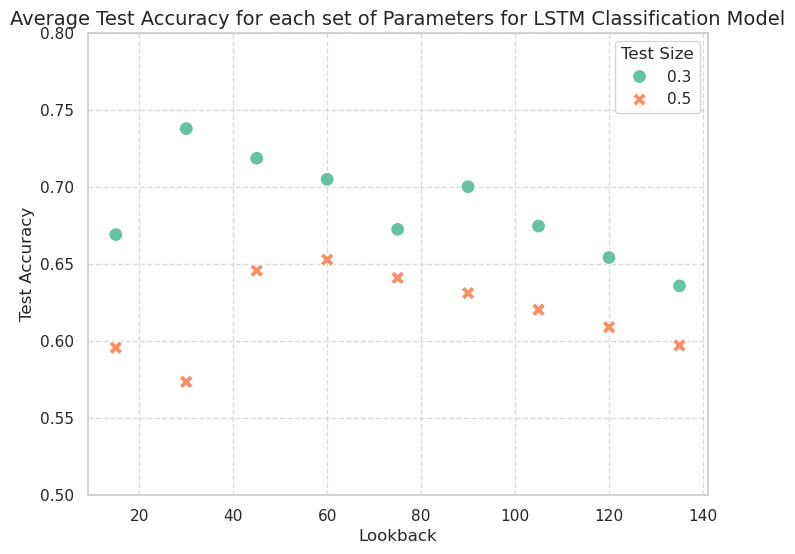

In [51]:

plt.figure(figsize=(8,6))
sns.scatterplot(
    data=df1_class_avg,
    x="lookback", y="test_acc",
    hue="test_size", style="test_size",
    palette="Set2", s=100
)

plt.title("Average Test Accuracy for each set of Parameters for LSTM Classification Model", fontsize=14)
plt.xlabel("Lookback", fontsize=12)
plt.ylabel("Test Accuracy", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.7)
plt.legend(title="Test Size")
plt.ylim(0.5, 0.8)   

plt.show()


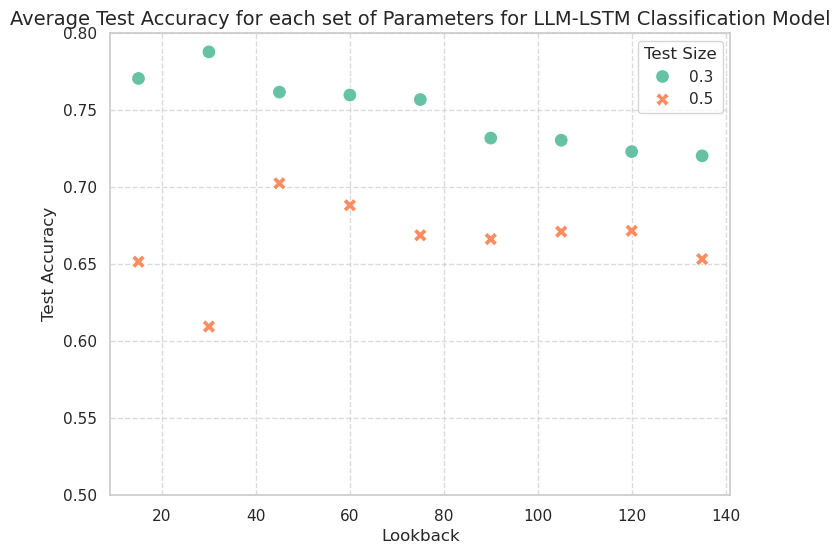

In [50]:
plt.figure(figsize=(8,6))
sns.scatterplot(
    data=df2_class_avg,
    x="lookback", y="test_acc",
    hue="test_size", style="test_size",
    palette="Set2", s=100
)

plt.title("Average Test Accuracy for each set of Parameters for LLM-LSTM Classification Model", fontsize=14)
plt.xlabel("Lookback", fontsize=12)
plt.ylabel("Test Accuracy", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.7)
plt.legend(title="Test Size")
plt.ylim(0.5, 0.8)   

plt.show()


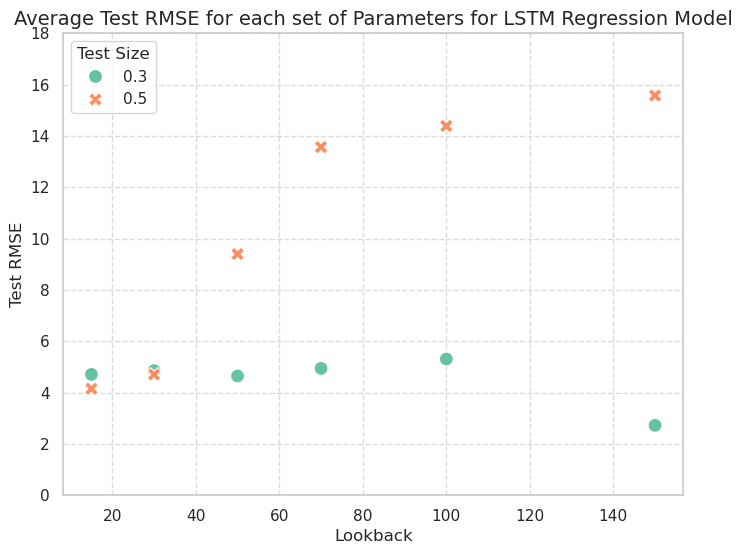

In [49]:
plt.figure(figsize=(8,6))
sns.scatterplot(
    data=df1_reg_avg,
    x="lookback", y="test_rmse",
    hue="test_size", style="test_size",
    palette="Set2", s=100
)

plt.title("Average Test RMSE for each set of Parameters for LSTM Regression Model", fontsize=14)
plt.xlabel("Lookback", fontsize=12)
plt.ylabel("Test RMSE", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.7)
plt.legend(title="Test Size")
plt.ylim(0, 18)   

plt.show()


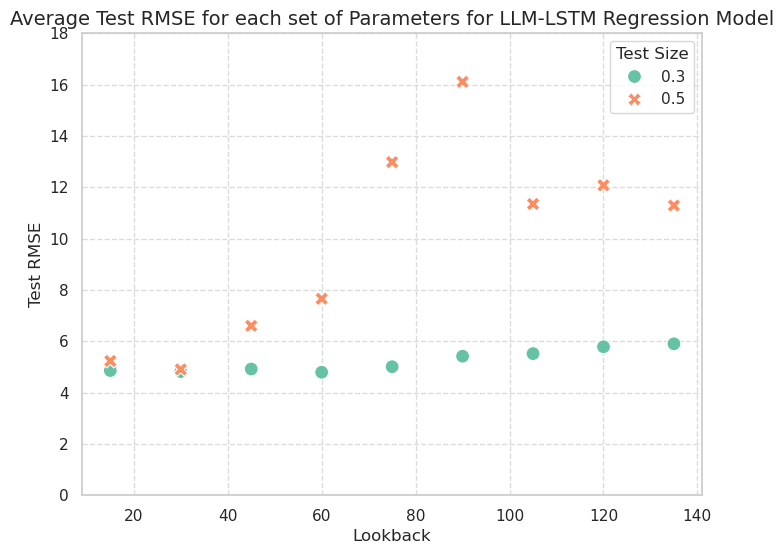

In [48]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,6))
sns.scatterplot(
    data=df2_reg_avg,
    x="lookback", y="test_rmse",
    hue="test_size", style="test_size",
    palette="Set2", s=100
)

plt.title("Average Test RMSE for each set of Parameters for LLM-LSTM Regression Model", fontsize=14)
plt.xlabel("Lookback", fontsize=12)
plt.ylabel("Test RMSE", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.7)
plt.legend(title="Test Size")

plt.ylim(0, 18)   
plt.show()



## Histogram

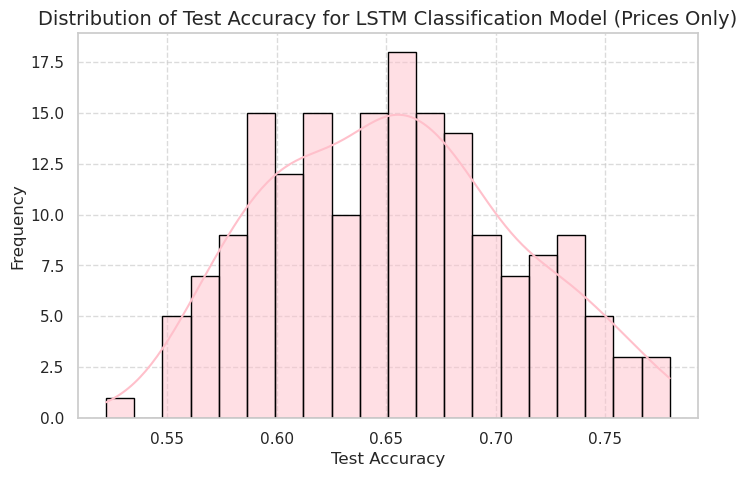

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set a clean style
sns.set(style="whitegrid")

# Create the histogram with KDE overlay
plt.figure(figsize=(8, 5))
sns.histplot(df1_class["test_acc"], bins=20, kde=True,
             color="pink", edgecolor="black")

# Add labels and title
plt.title("Distribution of Test Accuracy for LSTM Classification Model (Prices Only)", fontsize=14)
plt.xlabel("Test Accuracy", fontsize=12)
plt.ylabel("Frequency", fontsize=12)

# Show grid
plt.grid(True, linestyle="--", alpha=0.7)

plt.show()


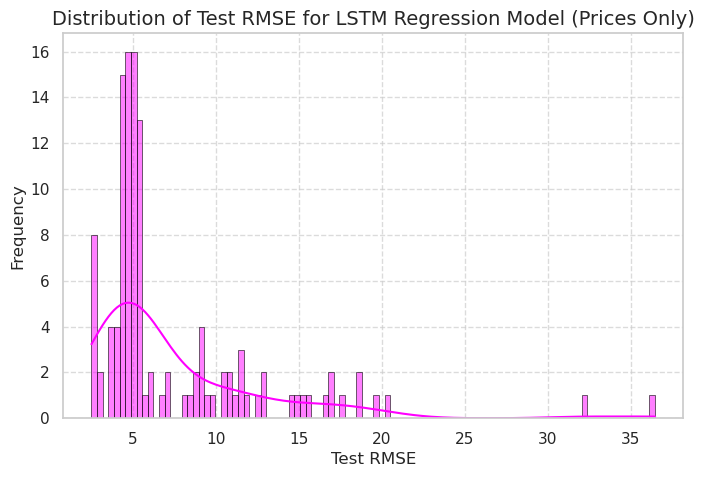

In [46]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set a clean style
sns.set(style="whitegrid")

# Create the histogram with KDE overlay
plt.figure(figsize=(8, 5))
sns.histplot(df1_reg["test_rmse"], bins=100, kde=True,
             color="magenta", edgecolor="black")

# Add labels and title
plt.title("Distribution of Test RMSE for LSTM Regression Model (Prices Only)", fontsize=14)
plt.xlabel("Test RMSE", fontsize=12)
plt.ylabel("Frequency", fontsize=12)

# Show grid
plt.grid(True, linestyle="--", alpha=0.7)

plt.show()

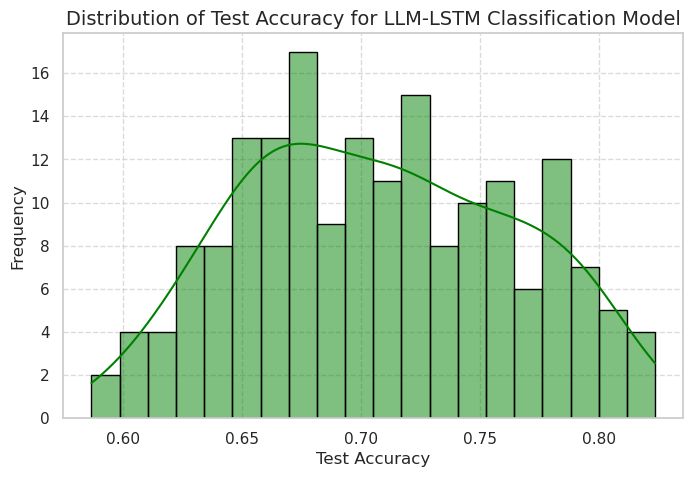

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set a clean style
sns.set(style="whitegrid")

# Create the histogram with KDE overlay
plt.figure(figsize=(8, 5))
sns.histplot(df2_class["test_acc"], bins=20, kde=True,
             color="green", edgecolor="black")

# Add labels and title
plt.title("Distribution of Test Accuracy for LLM-LSTM Classification Model", fontsize=14)
plt.xlabel("Test Accuracy", fontsize=12)
plt.ylabel("Frequency", fontsize=12)

# Show grid
plt.grid(True, linestyle="--", alpha=0.7)

plt.show()


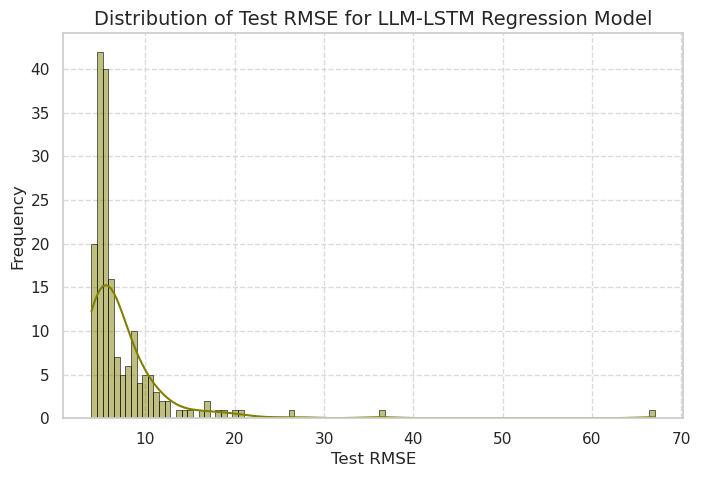

In [47]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set a clean style
sns.set(style="whitegrid")

# Create the histogram with KDE overlay
plt.figure(figsize=(8, 5))
sns.histplot(df2_reg["test_rmse"], bins=100, kde=True,
             color="olive", edgecolor="black")

# Add labels and title
plt.title("Distribution of Test RMSE for LLM-LSTM Regression Model", fontsize=14)
plt.xlabel("Test RMSE", fontsize=12)
plt.ylabel("Frequency", fontsize=12)

# Show grid
plt.grid(True, linestyle="--", alpha=0.7)

plt.show()

## Boxplots

/tmp/ipykernel_3022196/833546881.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="combo", y="test_acc", data=df1_class, palette="Dark2")


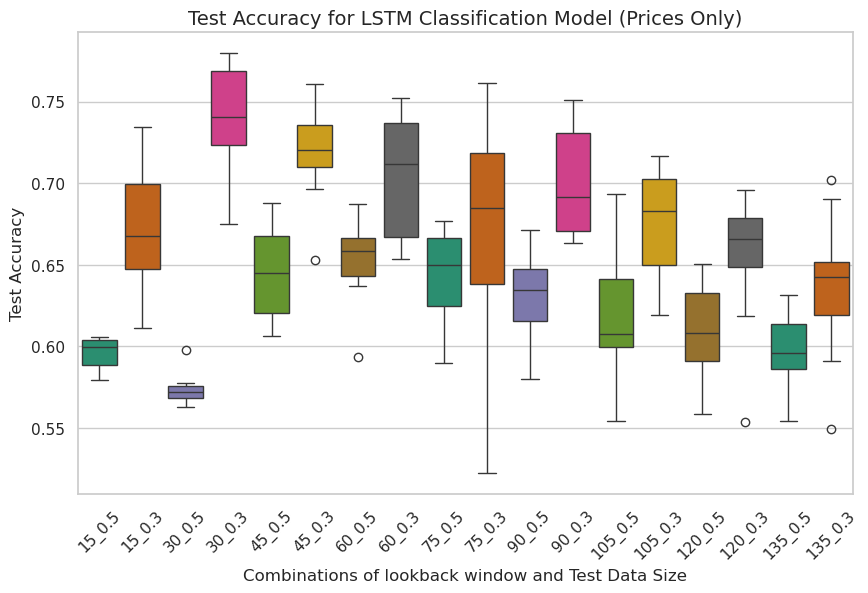

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

# We'll combine colA and colB into a single category
df1_class["combo"] = df1_class["lookback"].astype(str) + "_" + df1_class["test_size"].astype(str)

plt.figure(figsize=(10, 6))
sns.boxplot(x="combo", y="test_acc", data=df1_class, palette="Dark2")

# Add labels and title
plt.title("Test Accuracy for LSTM Classification Model (Prices Only)", fontsize=14)
plt.xlabel("Combinations of lookback window and Test Data Size", fontsize=12)
plt.ylabel("Test Accuracy", fontsize=12)

# Rotate x-axis labels if many categories
plt.xticks(rotation=45)

plt.show()


/tmp/ipykernel_3022196/1662247745.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="combo", y="test_rmse", data=df1_reg, palette="magma")


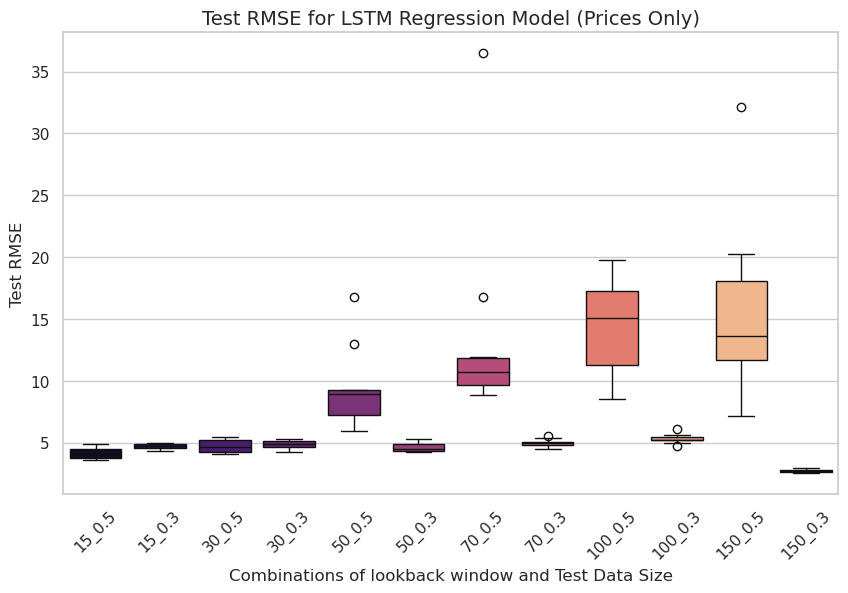

In [28]:

# We'll combine colA and colB into a single category
df1_reg["combo"] = df1_reg["lookback"].astype(str) + "_" + df1_reg["test_size"].astype(str)

plt.figure(figsize=(10, 6))
sns.boxplot(x="combo", y="test_rmse", data=df1_reg, palette="magma")

# Add labels and title
plt.title("Test RMSE for LSTM Regression Model (Prices Only)", fontsize=14)
plt.xlabel("Combinations of lookback window and Test Data Size", fontsize=12)
plt.ylabel("Test RMSE", fontsize=12)

# Rotate x-axis labels if many categories
plt.xticks(rotation=45)

plt.show()

/tmp/ipykernel_3022196/1057356993.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="combo", y="test_acc", data=df2_class, palette="summer")


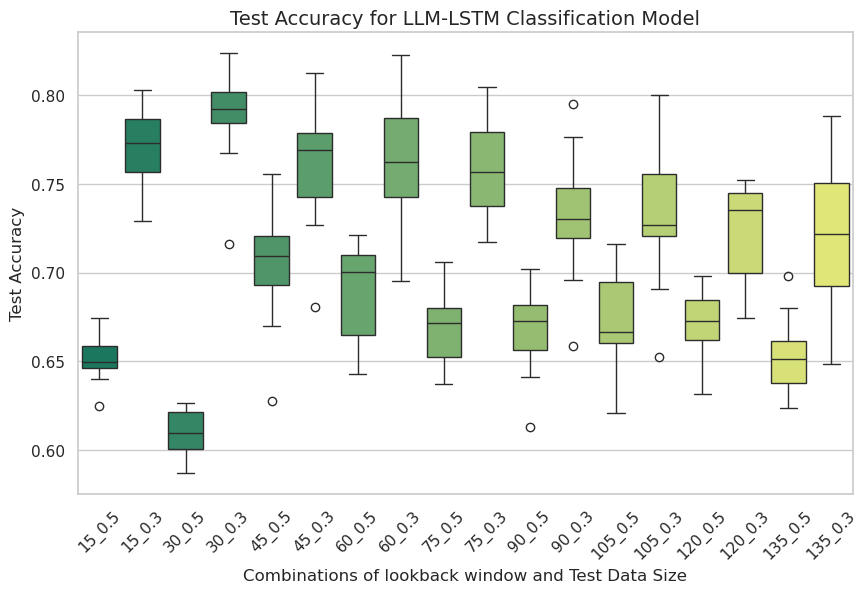

In [24]:
# We'll combine colA and colB into a single category
df2_class["combo"] = df2_class["lookback"].astype(str) + "_" + df2_class["test_size"].astype(str)

plt.figure(figsize=(10, 6))
sns.boxplot(x="combo", y="test_acc", data=df2_class, palette="summer")

# Add labels and title
plt.title("Test Accuracy for LLM-LSTM Classification Model", fontsize=14)
plt.xlabel("Combinations of lookback window and Test Data Size", fontsize=12)
plt.ylabel("Test Accuracy", fontsize=12)

# Rotate x-axis labels if many categories
plt.xticks(rotation=45)

plt.show()

/tmp/ipykernel_3022196/2013059289.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="combo", y="test_rmse", data=df2_reg, palette="cividis")


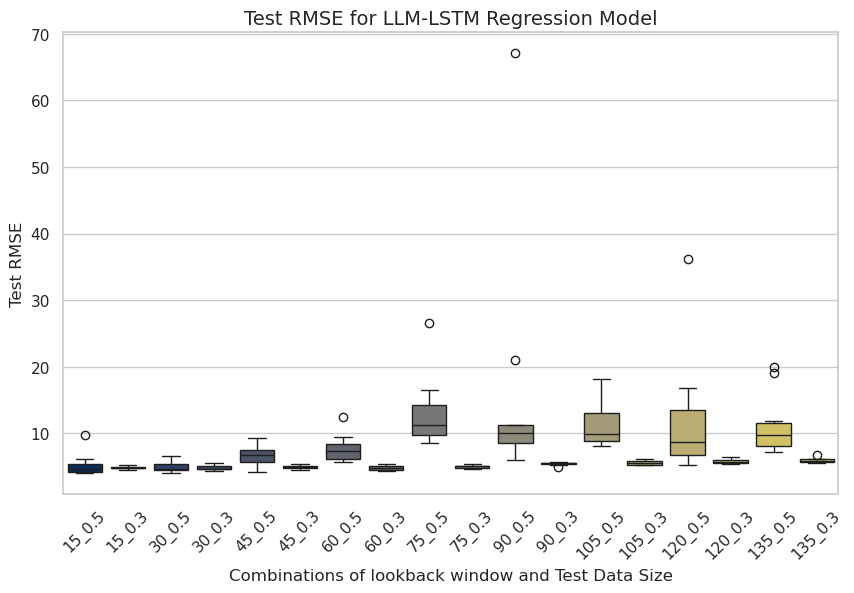

In [26]:
# We'll combine colA and colB into a single category
df2_reg["combo"] = df2_reg["lookback"].astype(str) + "_" + df2_reg["test_size"].astype(str)

plt.figure(figsize=(10, 6))
sns.boxplot(x="combo", y="test_rmse", data=df2_reg, palette="cividis")

# Add labels and title
plt.title("Test RMSE for LLM-LSTM Regression Model", fontsize=14)
plt.xlabel("Combinations of lookback window and Test Data Size", fontsize=12)
plt.ylabel("Test RMSE", fontsize=12)

# Rotate x-axis labels if many categories
plt.xticks(rotation=45)

plt.show()